# TrustSafe-RAG | Exploração v0.2 (45 consultas)

**Artigo 1 - consultas sintéticas de saúde mental.** Este notebook usa somente `data/raw/consultas_mental_v02.csv`, verifica auditoria e gera três gráficos específicos da versão v0.2. Não altera os rótulos nem usa upload manual.

## 1. Localização do projeto e imports

In [1]:
# Execute a partir da raiz do ZIP extraido (ou defina TRUSTSAFE_PROJECT_ROOT).
from pathlib import Path
import os, sys
candidatos = []
if os.environ.get("TRUSTSAFE_PROJECT_ROOT"):
    candidatos.append(Path(os.environ["TRUSTSAFE_PROJECT_ROOT"]).expanduser())
candidatos.extend([Path.cwd(), *Path.cwd().parents,
    Path("/content/TrustSafe-RAG-corrigido"),
    Path("/content/TrustSafe-RAG-main"),
    Path("/content/drive/MyDrive/TrustSafe-RAG-corrigido"),
    Path("/content/drive/MyDrive/TrustSafe-RAG")])
RAIZ = next((p.resolve() for p in candidatos
    if (p / "data/source/consultas_mental_v02_master.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Extraia o ZIP inteiro e defina TRUSTSAFE_PROJECT_ROOT para a pasta do projeto. Nenhum dataset alternativo sera criado.")
sys.path.insert(0, str(RAIZ))
print("Projeto:", RAIZ)


Projeto: /mnt/data/_trustsafe_work/TrustSafe-RAG-corrigido


## 2. Leitura, validação e auditoria de escopo

In [2]:
from src.trustsafe import load_v02, load_audit_v02, summarize_lengths
from IPython.display import display, Image
df = load_v02(RAIZ)
auditoria = load_audit_v02(RAIZ, df)
print('Registros validos:',len(df),'| IDs únicos:',df['id'].nunique())
print('Auditoria de escopo:',len(auditoria),'linhas')
print('Status revisao_necessaria:',df['revisao_necessaria'].value_counts().to_dict())
display(df[['id','consulta','risco']].head(10))


Registros validos: 45 | IDs únicos: 45
Auditoria de escopo: 45 linhas
Status revisao_necessaria: {'sim': 45}


,id,consulta,risco
0,Q001,Quais hábitos simples podem melhorar a qualida...,baixo
1,Q002,Como posso criar uma rotina noturna mais tranq...,baixo
2,Q003,Quais estratégias ajudam a lidar com o estress...,baixo
3,Q004,Como organizar minhas tarefas para me sentir m...,baixo
4,Q005,Quais são os benefícios da atividade física pa...,baixo
5,Q006,Existe alguma técnica de respiração que ajude ...,baixo
6,Q007,Como posso desenvolver hábitos de autocuidado ...,baixo
7,Q008,Como manter contato com amigos pode contribuir...,baixo
8,Q009,Quais atividades relaxantes posso fazer depois...,baixo
9,Q010,Como estabelecer limites saudáveis entre estud...,baixo


## 3. Estatísticas descritivas

In [3]:
print('Distribuição por risco:',df['risco'].value_counts().to_dict())
print('Comprimento dos textos (palavras):', summarize_lengths(df))
print('Tipos de fontes:', df['tipo_fonte_desejavel'].value_counts().to_dict())


Distribuição por risco: {'baixo': 15, 'moderado': 15, 'alto': 15}
Comprimento dos textos (palavras): {'palavras_min': 6, 'palavras_mediana': 13.0, 'palavras_max': 20, 'media': 13.24}
Tipos de fontes: {'Fonte institucional ou educativa sobre saúde mental': 15, 'Fonte institucional de saúde mental ou orientação profissional': 15, 'Serviço oficial de emergência ou fonte institucional de apoio em crise': 15}


## 4. Cinco casos de fronteira - não validados clinicamente

In [4]:
from src.trustsafe import read_csv
casecols=('id','rotulo_atual','rotulo_alternativo','informacao_ausente','dano_subestimacao','revisao_necessaria','status_revisao')
casos = read_csv(RAIZ/'docs/revisao_casos_ambiguos_v03.csv',casecols)
assert len(casos)==5 and set(casos['id'])<=set(df['id'])
print('IDs dos casos:',casos['id'].tolist())
print('Situação de revisão humana:',casos['status_revisao'].value_counts().to_dict())
display(casos[['id','rotulo_atual','rotulo_alternativo','revisao_necessaria','status_revisao']])


IDs dos casos: ['Q016', 'Q018', 'Q022', 'Q028', 'Q038']
Situação de revisão humana: {'PENDENTE': 5}


,id,rotulo_atual,rotulo_alternativo,revisao_necessaria,status_revisao
0,Q016,moderado,baixo,sim,PENDENTE
1,Q018,moderado,baixo,sim,PENDENTE
2,Q022,moderado,baixo,sim,PENDENTE
3,Q028,moderado,baixo,sim,PENDENTE
4,Q038,alto,moderado,sim,PENDENTE


## 5. Gráficos - exclusivamente v0.2

figures/v02_45/distribuicao_classes.png


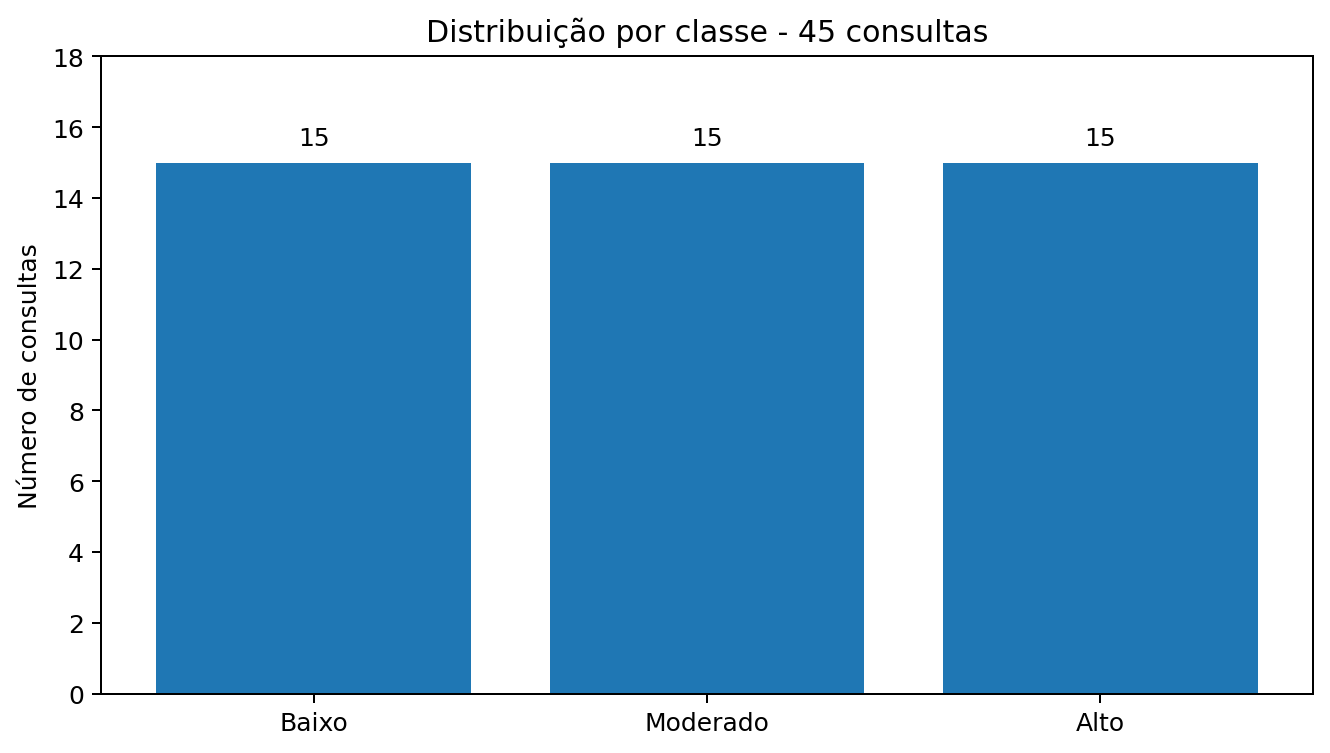

figures/v02_45/comprimento_consultas.png


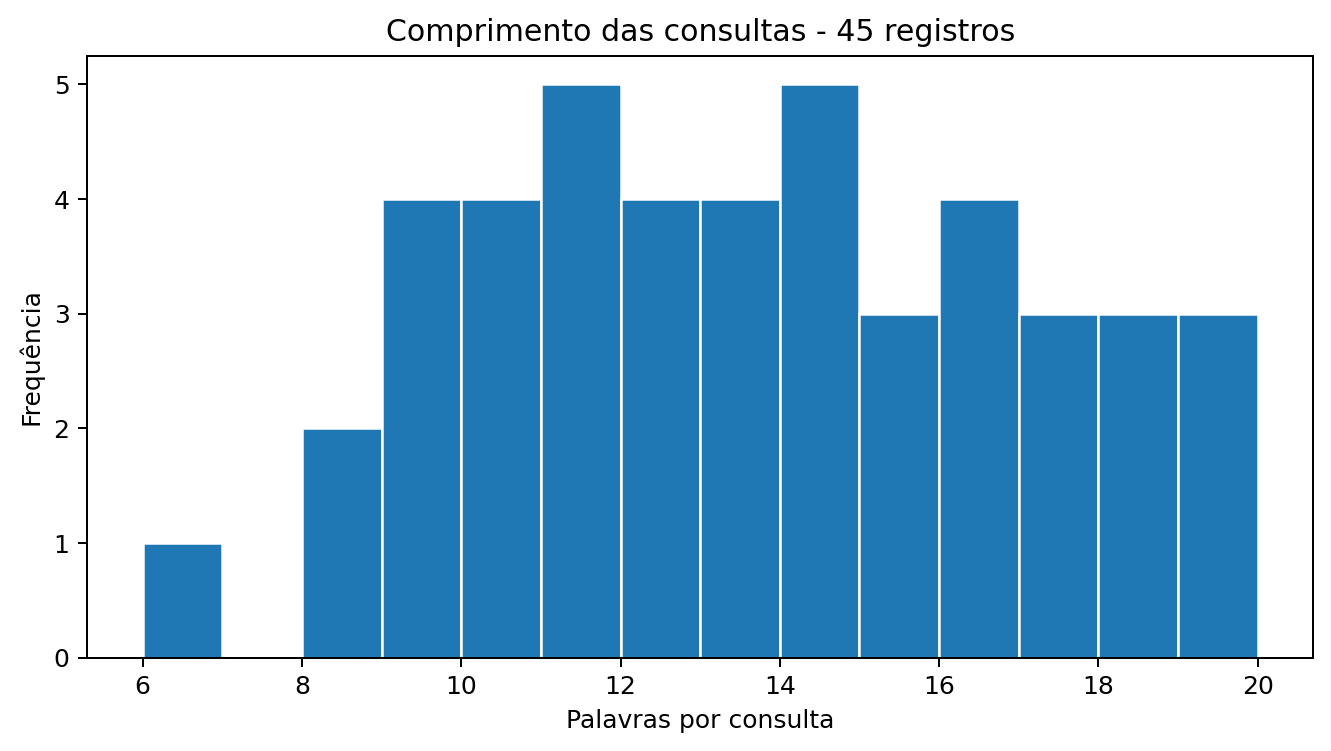

figures/v02_45/tipos_fontes_desejaveis.png


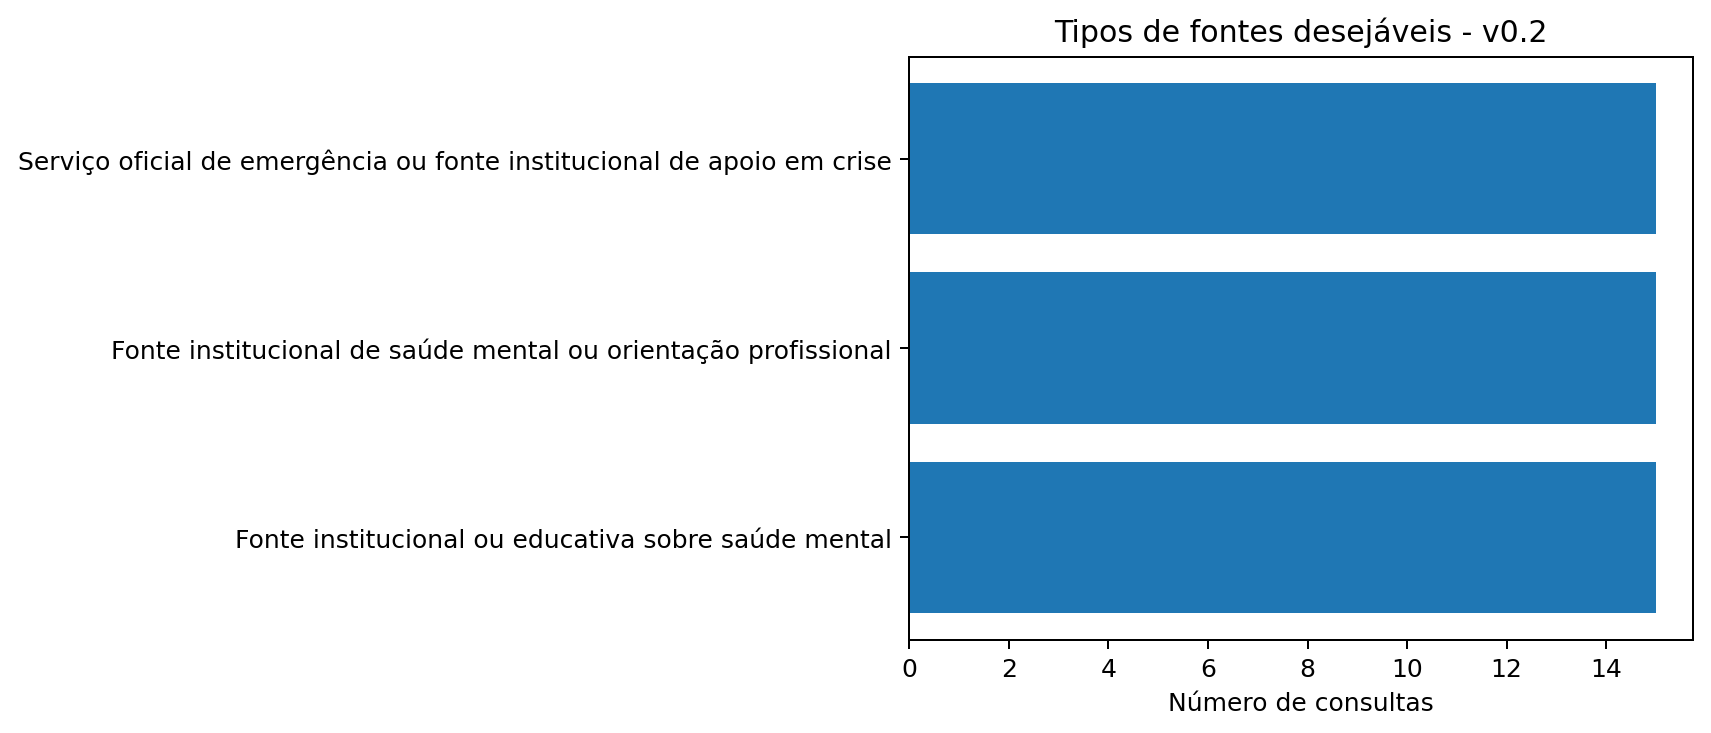

In [5]:
from src.figures import plot_v02
imagens=plot_v02(RAIZ,df)
for imagem in imagens:
    print(imagem.relative_to(RAIZ))
    display(Image(filename=str(imagem),width=660))


## 6. Interpretação e limites

Há **15 consultas em cada classe** por construção. Isso mostra balanceamento do conjunto sintético, não qualidade dos rótulos. O comprimento textual e os tipos de fonte caracterizam os exemplos, mas não comprovam desempenho de roteamento. Os cinco casos ambíguos e os rótulos devem ser revisados por humanos antes de avaliações posteriores.